# nb07 — Motifs in E2-associated accessibility changes

## Question
Which sequence motifs are enriched in peaks more accessible under E2, and which
are enriched in peaks less accessible under E2, relative to comparable background
peaks? Compare MCF7 and T47D, and inspect the corresponding TF RNA and nb06 pathway
context. Motifs indicate sequence compatibility, not actual TF binding or activity.

This is an exploratory extension of nb05–nb06, not a reproduction of scMKL motif
group weights. Scanpy supplies the upstream QC, RNA statistics and ATAC workflow;
MOODS performs DNA motif scanning here, since Scanpy does not supply that step.

## Coordinate audit: unresolved, explicitly tested
GEO records hg38. The original authors' pinned code reads Cell Ranger peak matrices
into Signac and creates a separate MACS2 assay, but does not document the exact
export that generated our GEO TSV row names. Neither coordinate convention is
declared confirmed.

For a name chr-start-end, evaluate:
- zero-based half-open: hg38 bases [start, end);
- one-based closed: hg38 bases [start-1, end).

Scan the longer interval once, then retain only hits fully inside each interval.
The shorter interval is common to both hypotheses. Matching, peak identifiers and
foregrounds are held fixed between coordinate hypotheses; only motif presence
changes. GC and length matching use the common interval. This tests the remaining
one-base boundary ambiguity and does not resolve its historical provenance.
No definitive binding-site BED coordinates or validated peak-gene links are exported.

## Frozen resources and sequence QC
- UCSC hg38 2bit, verified against UCSC's published MD5 and recorded SHA256.
- JASPAR2024 CORE vertebrates, non-redundant PFMs (fixed release; not claimed latest).
- Boyle Lab hg38 ENCODE blacklist v2, frozen by SHA256.
- Preserve the resource URLs, checksums and retrieval date in configs/motif_references.json.

Scan the union of nb05 tested peaks. Keep chr1–22, chrX and chrY only; do not guess
aliases for other contigs. Exclude invalid intervals, any blacklist overlap under
either coordinate hypothesis, and sequences containing bases outside A/C/G/T.
Soft-masked repeat bases are uppercased and included. Sequence exclusion reasons
are saved for every input peak; original nb05 objects and counts are unchanged.

## Motif scan
Use MOODS-python 1.9.4.1, both strands, a uniform A/C/G/T background, total column
pseudocount 0.01 and per-position motif threshold p <= 1e-4. MOODS converts the
PFMs to natural-log odds matrices and computes score thresholds. This site
threshold is not a motif-enrichment FDR. Count each peak once per motif regardless
of the number of sites. Retain IDs, names, motif widths and thresholds.

Both coordinate presence matrices are cached with settings/reference/peak keys.
Changing the inputs invalidates the cache. Motifs can be highly similar; multiple
significant motifs do not imply distinct TF mechanisms.

## Foregrounds, backgrounds and enrichment
Reuse nb05 candidate definitions unchanged (cell-level BH q <= 0.05, absolute
accessibility-fraction difference >= 0.05, and adjusted/raw direction agreement).

Analyze E2-higher and Vehicle-higher peaks separately, per cell line. The latter
are peaks less accessible under E2; enriched motifs in those peaks are not called
“downregulated TFs.”

Controls are eligible tested peaks outside **both** candidate sets. They are
non-candidates, not proven invariant regions. Match each foreground to one unique
control within the same chromosome, without replacement within each comparison.
Use deterministic nearest-neighbor matching on:
- GC fraction (absolute difference <= 0.05);
- natural log length (absolute difference <= 0.25);
- logit accessibility (absolute difference <= 0.5), using the equal-condition mean
  of E2 and Vehicle detection fractions, clipped to [1e-6, 1-1e-6].

Search the nearest 200 controls in scaled feature space. Process foregrounds with
the fewest eligible matches first; select the nearest unused control, with peak
name tie breaking. Save exact pairs and unmatched foregrounds. Controls may be
reused across separate comparisons, never twice within one comparison.

Test motif enrichment using a one-sided exact matched-pair binomial test:
b = pairs with a foreground hit only; c = pairs with a background hit only;
P = Pr[Binomial(b+c, 0.5) >= b]. With no discordant pairs, P = 1.
Report motif fractions, b/c counts and smoothed log2 paired odds
log2[(b+0.5)/(c+0.5)]. With fewer than 20 matched pairs, P remains missing.
These are peak-pair sequence tests, not cell-level or biological-replicate tests.

Apply BH correction within each comparison and globally across all motifs,
two lines, two directions, two detection scenarios and two coordinate hypotheses.
The global q is the primary display value. Peak dependence, correlated motifs,
foreground selection and residual technical confounding limit formal inference.

Require >=80% foreground match coverage, >=20 pairs, and absolute standardized
mean differences <=0.1 for all three matching features before labeling a motif
a priority candidate at global q <=0.05. These are predeclared review thresholds,
not proof of adequate control of all confounders. All results remain available.

## Sensitivity and RNA/pathway context
Repeat the matching and testing after removing peaks detected in only one
condition from both foreground and control eligibility. This can remove genuine
biology as well as library-specific effects; neither result is privileged as truth.

Match motif labels to RNA-tested gene symbols after uppercasing and removing
terminal (var.N) suffixes; split :: dimers into components. This is candidate label
matching across a vertebrate motif collection, not validated orthology or alias
resolution. Retain unmatched labels. RNA fold change and RNA BH q are contextual;
TF RNA expression is not TF protein activity.

For the top 10 priority motifs per line/direction/detection scenario under the shorter coordinate hypothesis, list motif-bearing
matched foreground peaks that have provisional nb06 nearby-gene assignments.
Show their Hallmark membership and existing RNA NES/FDR and nb06 agreement.
These are traceable proximity intersections, not TF targets or pathway-enrichment
tests. Nearby-gene uncertainties from nb06 remain unchanged.

## Outputs and reproduction
Run notebooks/nb07_motif_analysis.ipynb after nb04–nb06. The notebook embeds its
implementation, settings and frozen reference manifest, installs missing scanner
dependencies, and downloads missing references with checksum checks. The hg38
reference is about 800 MB. Colab needs the project inputs in Drive; local execution
does not test interactive Drive authorization.

results/tables/nb07 contains sequence exclusions, all motif tests, background pairs
and balance, sensitivity/cross-line comparisons, TF RNA and pathway context,
reference provenance and validation. results/figures/nb07 contains enrichment and
matching-quality plots. Large presence matrices remain in ignored data/processed/nb07.
Upstream inputs are verified unchanged by SHA256.

## References
- [Original study analysis code](https://github.com/ohsu-cedar-comp-hub/BC_estrogen_TITAN_paper2022/blob/d8cbe099a81c7fb5bd148a845bacba17419feb8e/scripts/multiomics_analysis.md)
- [UCSC hg38 reference](https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/)
- [JASPAR 2024 documentation](https://jaspar2024.elixir.no/docs/) and [downloads](https://jaspar2024.elixir.no/downloads/)
- [MOODS](https://github.com/jhkorhonen/MOODS)
- [ENCODE blacklist](https://github.com/Boyle-Lab/Blacklist)
- [Exact matched-pair testing](https://www.statsmodels.org/stable/generated/statsmodels.stats.contingency_tables.mcnemar.html)


## 1. Locate project and prepare the environment

In [1]:
try:
    from google.colab import drive
except ImportError:
    IN_COLAB=False
else:
    IN_COLAB=True
    drive.mount('/content/drive')
from pathlib import Path
import os,sys,json,subprocess,importlib.util,importlib.metadata
BASE=Path('/content/drive/MyDrive/breast-cancer-multiome-estrogen') if IN_COLAB else Path(os.environ.get('MULTIOME_PROJECT_ROOT',Path.cwd())).resolve()
if BASE.name=='notebooks': BASE=BASE.parent
packages={'numpy':'numpy','pandas':'pandas','scipy':'scipy','statsmodels':'statsmodels',
          'matplotlib':'matplotlib','MOODS':'MOODS-python==1.9.4.1','py2bit':'py2bit==0.3.3'}
missing=[v for k,v in packages.items() if importlib.util.find_spec(k) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
VERSIONS={x.split('==')[0]:importlib.metadata.version(x.split('==')[0]) for x in packages.values()}
for line in ('MCF7','T47D'):
    assert (BASE/f'data/processed/{line}_nb05_da_all.tsv').exists(),'Run nb05 first.'
    assert (BASE/f'results/tables/nb06/{line}_provisional_peak_gene_links.tsv').exists(),'Run nb06 first.'
print(BASE, VERSIONS)


/home/shoko/breast-cancer-multiome-estrogen {'numpy': '2.4.6', 'pandas': '2.3.3', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.11.2', 'MOODS-python': '1.9.4.1', 'py2bit': '0.3.3'}


## 2. Coordinate uncertainty and frozen resources

In [2]:
CONFIG=json.loads('{"seed": 42, "motif_site_pvalue": 0.0001, "pseudocount_total_per_column": 0.01, "sequence_background": [0.25, 0.25, 0.25, 0.25], "standard_chromosomes": ["chr1", "chr2", "chr3", "chr4", "chr5", "chr6", "chr7", "chr8", "chr9", "chr10", "chr11", "chr12", "chr13", "chr14", "chr15", "chr16", "chr17", "chr18", "chr19", "chr20", "chr21", "chr22", "chrX", "chrY"], "coordinate_hypotheses": ["zero_based_half_open", "one_based_closed"], "minimum_matched_pairs": 20, "matching_calipers": {"gc_fraction": 0.05, "log_length": 0.25, "logit_accessibility": 0.5}, "matching_nearest_candidates": 200, "minimum_foreground_match_fraction": 0.8, "maximum_absolute_standardized_mean_difference": 0.1, "motif_enrichment_fdr": 0.05, "sensitivity_scenarios": ["all_candidates", "shared_detection"], "site_scan_window": 7, "method": "one-sided exact matched-pair binomial motif enrichment; BH within comparison and across all comparisons", "interpretation": "exploratory sequence enrichment, not binding/activity or replicate-supported treatment inference"}')
REFERENCES=json.loads('{"retrieved_date": "2026-10-11", "assembly": "hg38", "motif_release": "JASPAR2024 CORE vertebrates non-redundant", "genome_official_MD5_verified": true, "resources": {"hg38.2bit": {"url": "https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/hg38.2bit", "path": "data/raw/reference/nb07/hg38.2bit", "size": 835393456, "sha256": "1f67aaa17a77b327738fe750ab37430a85dddf73c7d9189385ad1839259acec0", "md5": "dcc3ea27079aa6dc3f9deccd7275e0f8"}, "hg38_md5sum.txt": {"url": "https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/md5sum.txt", "path": "data/raw/reference/nb07/hg38_md5sum.txt", "size": 720, "sha256": "25c4eb8362dcfb6e9bff1a6ab1b9d11fcf2334dce8a6984a091c59851f6e1145", "md5": "57face159b2845e2f58601d0050db7f7"}, "JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt": {"url": "https://jaspar2024.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt", "path": "data/raw/reference/nb07/JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt", "size": 283814, "sha256": "2a6c7c24afb0614ed418c9f02b68845adebf38f80f6cebabbcd5de804eaacb59", "md5": "60d87dabb351150bd6394f35874ca2ea"}, "hg38-blacklist.v2.bed.gz": {"url": "https://raw.githubusercontent.com/Boyle-Lab/Blacklist/master/lists/hg38-blacklist.v2.bed.gz", "path": "data/raw/reference/nb07/hg38-blacklist.v2.bed.gz", "size": 5867, "sha256": "c92e763af17271446194991e71917ac220593a5a3d40a06667be24178ef08cf2", "md5": "83fe6bf8187a64dee8079b80f75ba289"}}}')
COORDINATE_AUDIT=json.loads('{"audited_date": "2026-10-11", "assembly": "hg38", "coordinate_origin_confirmed": false, "authors_code_url": "https://github.com/ohsu-cedar-comp-hub/BC_estrogen_TITAN_paper2022/blob/d8cbe099a81c7fb5bd148a845bacba17419feb8e/scripts/multiomics_analysis.md", "authors_code_sha256": "a1cf1c42360678963a0f6b68ea7987d8bb39659d75bbcaf40be803398f53e77f", "evidence": "Original code reads Cell Ranger H5 peaks into Signac and also creates a separate MACS2 peak assay. The exact export producing our GEO ATAC TSV row names is not documented in this file. This does not establish the coordinate origin of our matrices.", "policy": "Do not declare either origin correct. Scan both [start,end) and [start-1,end) hypotheses on hg38; use the same peak IDs and matching pairs. Report coordinate sensitivity. The shorter interval is shared by both hypotheses; no definitive genomic binding-site exports."}')
print(json.dumps(COORDINATE_AUDIT,indent=2))

{
  "audited_date": "2026-10-11",
  "assembly": "hg38",
  "coordinate_origin_confirmed": false,
  "authors_code_url": "https://github.com/ohsu-cedar-comp-hub/BC_estrogen_TITAN_paper2022/blob/d8cbe099a81c7fb5bd148a845bacba17419feb8e/scripts/multiomics_analysis.md",
  "authors_code_sha256": "a1cf1c42360678963a0f6b68ea7987d8bb39659d75bbcaf40be803398f53e77f",
  "evidence": "Original code reads Cell Ranger H5 peaks into Signac and also creates a separate MACS2 peak assay. The exact export producing our GEO ATAC TSV row names is not documented in this file. This does not establish the coordinate origin of our matrices.",
  "policy": "Do not declare either origin correct. Scan both [start,end) and [start-1,end) hypotheses on hg38; use the same peak IDs and matching pairs. Report coordinate sensitivity. The shorter interval is shared by both hypotheses; no definitive genomic binding-site exports."
}


In [3]:
import urllib.request,hashlib
for name,ref in REFERENCES['resources'].items():
    path=BASE/ref['path'];path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists():
        print('Downloading',name,flush=True)
        temporary=path.with_name(path.name+'.partial')
        with urllib.request.urlopen(ref['url'],timeout=120) as response,temporary.open('wb') as out:
            while chunk:=response.read(1048576):out.write(chunk)
        h=hashlib.sha256()
        with temporary.open('rb') as f:
            while chunk:=f.read(1048576):h.update(chunk)
        assert h.hexdigest()==ref['sha256'],'Reference changed: review before continuing.'
        temporary.replace(path)
print('References available; checksums verified again by the analysis.')


References available; checksums verified again by the analysis.


## 3. Embedded implementation

In [4]:
"""Sequence motif enrichment with auditable matched backgrounds and coordinate sensitivity."""
from pathlib import Path
import gzip,hashlib,json,re,time
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import py2bit
import MOODS.scan,MOODS.tools
from scipy.spatial import cKDTree
from scipy.special import logit
from scipy.stats import binom
from statsmodels.stats.multitest import multipletests
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

def sha256(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for b in iter(lambda:f.read(1048576),b""):h.update(b)
    return h.hexdigest()

def save_tsv(df,path):
    df.to_csv(path,sep="\t",index=False,float_format="%.9g")

def parse_jaspar(path):
    entries=[]
    lines=Path(path).read_text().splitlines()
    for i in range(0,len(lines),5):
        motif_id,name=lines[i][1:].split(None,1)
        matrix=[]
        for base,line in zip("ACGT",lines[i+1:i+5]):
            assert line.startswith(base)
            matrix.append([float(x) for x in re.findall(r"[\d.]+",line)])
        assert len({len(v) for v in matrix})==1
        entries.append({"motif_id":motif_id,"motif_name":name,"matrix":matrix})
    assert len({m["motif_id"] for m in entries})==len(entries)
    return entries

def build_scanner(motifs,config):
    bg=config["sequence_background"]
    forward=[MOODS.tools.log_odds(m["matrix"],bg,config["pseudocount_total_per_column"]) for m in motifs]
    matrices=forward+[MOODS.tools.reverse_complement(m,4) for m in forward]
    thresholds=[MOODS.tools.threshold_from_p(m,bg,config["motif_site_pvalue"]) for m in matrices]
    scanner=MOODS.scan.Scanner(config["site_scan_window"])
    scanner.set_motifs(matrices,bg,thresholds)
    return scanner,thresholds[:len(motifs)]

def scan_union_sequence(scanner,seq,n_motifs):
    """Union sequence is [s-1,e); both hypotheses differ only at leftmost base."""
    common=np.zeros(n_motifs,dtype=bool);extended=common.copy()
    results=scanner.scan(seq)
    for j,matches in enumerate(results):
        if matches:
            idx=j%n_motifs
            extended[idx]=True
            if any(hit.pos>=1 for hit in matches):common[idx]=True
    return common,extended

def sequence_qc(root,da_tables,refs,config):
    peaks=sorted(set().union(*(set(x.peak) for x in da_tables.values())))
    genome=py2bit.open(str(root/refs["resources"]["hg38.2bit"]["path"]))
    sizes=genome.chroms()
    blacklist=pd.read_csv(root/refs["resources"]["hg38-blacklist.v2.bed.gz"]["path"],
                          sep="\t",header=None,usecols=[0,1,2],names=["chrom","start","end"])
    lookup={}
    for chrom,g in blacklist.groupby("chrom"):
        g=g.sort_values("start")
        lookup[chrom]=(g.start.to_numpy(),np.maximum.accumulate(g.end.to_numpy()))
    records=[];sequences={}
    for peak in peaks:
        chrom,start,end=peak.rsplit("-",2);start=int(start);end=int(end)
        reason="eligible";seq=""
        if chrom not in config["standard_chromosomes"]:reason="nonstandard_chromosome"
        elif chrom not in sizes:reason="missing_reference_chromosome"
        elif start<1 or end<=start or end>sizes[chrom]:reason="invalid_interval_under_one_or_both_hypotheses"
        else:
            if chrom in lookup:
                starts,ends=lookup[chrom];i=np.searchsorted(starts,end,side="left")-1
                if i>=0 and ends[i]>start-1:reason="overlaps_blacklist_under_at_least_one_hypothesis"
            if reason=="eligible":
                seq=genome.sequence(chrom,start-1,end).upper()
                if len(seq)!=end-start+1:raise ValueError("Genome extraction length mismatch")
                if set(seq)-set("ACGT"):reason="ambiguous_sequence"
        common=seq[1:] if seq else ""
        gc=(common.count("G")+common.count("C"))/len(common) if common else np.nan
        records.append((peak,chrom,start,end,end-start,gc,reason))
        if reason=="eligible":sequences[peak]=seq
    genome.close()
    return pd.DataFrame(records,columns=["peak","chrom","start_as_supplied","end_as_supplied",
             "length_common_interval","gc_fraction","sequence_status"]),sequences

def matched_background(foreground,controls,config):
    """Deterministic 1:1 matching without replacement within chromosome and calipers."""
    features=["gc_fraction","log_length","logit_accessibility"]
    scales=np.array([config["matching_calipers"][x] for x in features])
    pairs=[];unmatched=[]
    for chrom,fg in foreground.groupby("chrom",sort=True):
        fg=fg.sort_values("peak");bg=controls.loc[controls.chrom==chrom].sort_values("peak")
        if bg.empty:
            unmatched.extend(fg.peak.tolist());continue
        f=fg[features].to_numpy();b=bg[features].to_numpy()
        k=min(config["matching_nearest_candidates"],len(bg))
        distances,indices=cKDTree(b/scales).query(f/scales,k=k)
        if k==1:distances=distances[:,None];indices=indices[:,None]
        choices=[]
        for i in range(len(fg)):
            valid=np.all(np.abs((b[indices[i]]-f[i])/scales)<=1+1e-12,axis=1)
            choices.append([(float(d),int(j)) for d,j in zip(distances[i][valid],indices[i][valid])])
        used=set()
        for i in sorted(range(len(fg)),key=lambda i:(len(choices[i]),fg.iloc[i].peak)):
            options=[(d,j) for d,j in choices[i] if j not in used]
            if not options:unmatched.append(fg.iloc[i].peak);continue
            distance,j=min(options,key=lambda x:(x[0],bg.iloc[x[1]].peak));used.add(j)
            record={"foreground_peak":fg.iloc[i].peak,"background_peak":bg.iloc[j].peak,
                    "chrom":chrom,"scaled_euclidean_distance":distance}
            for z,feature in enumerate(features):
                record["foreground_"+feature]=f[i,z];record["background_"+feature]=b[j,z]
            pairs.append(record)
    columns=["foreground_peak","background_peak","chrom","scaled_euclidean_distance"]+[
        side+"_"+f for f in features for side in ["foreground","background"]]
    return pd.DataFrame(pairs,columns=columns),unmatched

def balance_report(pairs):
    rows=[]
    for feature in ["gc_fraction","log_length","logit_accessibility"]:
        a=pairs["foreground_"+feature].to_numpy();b=pairs["background_"+feature].to_numpy()
        if len(a)<2:smd=np.nan
        else:
            denom=np.sqrt((a.var(ddof=1)+b.var(ddof=1))/2)
            smd=(a.mean()-b.mean())/denom if denom>0 else 0.0 if a.mean()==b.mean() else np.inf
        rows.append(dict(feature=feature,foreground_mean=a.mean() if len(a) else np.nan,
                         background_mean=b.mean() if len(b) else np.nan,
                         standardized_mean_difference=smd,
                         maximum_absolute_pair_difference=float(np.abs(a-b).max()) if len(a) else np.nan))
    return pd.DataFrame(rows)

def paired_enrichment(foreground_hits,background_hits):
    assert foreground_hits.shape==background_hits.shape
    fg_only=(foreground_hits & ~background_hits).sum(axis=0)
    bg_only=(~foreground_hits & background_hits).sum(axis=0)
    discordant=fg_only+bg_only
    p=binom.sf(fg_only-1,discordant,.5)
    p=np.where(discordant==0,1.0,p)
    return pd.DataFrame({"foreground_hits":foreground_hits.sum(axis=0),
          "background_hits":background_hits.sum(axis=0),"foreground_only_pairs":fg_only,
          "background_only_pairs":bg_only,"paired_log2_odds_smoothed":np.log2((fg_only+.5)/(bg_only+.5)),
          "peak_pair_p":p})

def motif_gene_labels(name,rna_genes):
    # Case-normalized motif label candidates; not an orthology or TF-target mapping.
    parts=name.split("::")
    candidates=[re.sub(r"\(var\.\d+\)$","",x).upper() for x in parts]
    return [(x,x in rna_genes) for x in candidates]

def plots(enrichment,balance,root):
    directory=root/"results/figures/nb07";directory.mkdir(parents=True,exist_ok=True)
    for line in ["MCF7","T47D"]:
        for scenario in ["all_candidates","shared_detection"]:
            primary=enrichment.loc[(enrichment.cell_line==line)&
              (enrichment.scenario==scenario)&
              (enrichment.coordinate_hypothesis=="zero_based_half_open")]
            fig,axes=plt.subplots(1,2,figsize=(15,8))
            for ax,direction,title in zip(axes,["E2","Vehicle"],["More accessible under E2","Less accessible under E2"]):
                d=primary.loc[primary.direction==direction].sort_values(["global_BH_q","peak_pair_p","motif_id"]).head(15).iloc[::-1]
                x=-np.log10(d.global_BH_q.clip(lower=1e-300))
                colors=np.where(d.priority_candidate,"#bd5945","#9ca3af")
                ax.barh(np.arange(len(d)),x,color=colors)
                ax.set_yticks(np.arange(len(d)),d.motif_name+" "+d.motif_id,fontsize=9)
                ax.axvline(-np.log10(.05),color="black",ls="--",lw=.8)
                ax.set_xlabel("−log10 global motif BH q");ax.set_title(title)
            fig.suptitle(f"{line}: matched-background motif enrichment ({scenario})\nPrimary coordinate hypothesis; orange requires acceptable matching and q ≤ 0.05")
            fig.tight_layout(rect=(0,0,1,.93));fig.savefig(directory/(f"{line}_motif_enrichment.png" if scenario=="all_candidates" else f"{line}_motif_enrichment_shared_detection.png"),dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,6))
    for feature,g in balance.groupby("feature"):
        labels=g.cell_line+" / "+g.direction+" / "+g.scenario
        ax.scatter(g.standardized_mean_difference,labels,label=feature,s=45)
    ax.axvline(0,color="gray");ax.axvline(.1,color="gray",ls="--");ax.axvline(-.1,color="gray",ls="--")
    ax.set_xlabel("Standardized mean difference after matching")
    ax.set_title("GC, peak length and accessibility balance\nDashed lines: ±0.1 review threshold")
    ax.legend(loc="best");fig.tight_layout();fig.savefig(directory/"background_balance.png",dpi=160);plt.close(fig)

def run_motifs(root,config,refs,coordinate_audit):
    root=Path(root);tables=root/"results/tables/nb07";tables.mkdir(parents=True,exist_ok=True)
    cache=root/"data/processed/nb07";cache.mkdir(parents=True,exist_ok=True)
    sources=[root/f"data/processed/{line}_nb05_da_all.tsv" for line in ["MCF7","T47D"]]+[
        root/f"results/tables/nb04/{line}_deg_all.tsv" for line in ["MCF7","T47D"]]+[
        root/f"results/tables/nb06/{line}_provisional_peak_gene_links.tsv" for line in ["MCF7","T47D"]]+[
        root/"results/tables/nb06/all_pathway_scenarios.tsv",root/"configs/hallmark_v7.json"]
    before={str(x.relative_to(root)):sha256(x) for x in sources}
    for name,ref in refs["resources"].items():
        assert sha256(root/ref["path"])==ref["sha256"],f"Reference changed: {name}"
    data={line:pd.read_csv(root/f"data/processed/{line}_nb05_da_all.tsv",sep="\t") for line in ["MCF7","T47D"]}
    motifs=parse_jaspar(root/refs["resources"]["JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt"]["path"])
    motif_table=pd.DataFrame([{k:v for k,v in m.items() if k!="matrix"} for m in motifs])
    motif_table["length"]=[len(m["matrix"][0]) for m in motifs]
    print("Sequence QC and reference verification...",flush=True)
    qc,sequences=sequence_qc(root,data,refs,config)
    save_tsv(qc,tables/"peak_sequence_qc.tsv")
    eligible=qc.loc[qc.sequence_status=="eligible"].copy().sort_values("peak").reset_index(drop=True)
    peak_names=eligible.peak.tolist();peak_index={p:i for i,p in enumerate(peak_names)}
    key=hashlib.sha256(json.dumps({"refs":refs,"config":config,"peaks":peak_names,
                     "implementation":"nb07-v1"},sort_keys=True).encode()).hexdigest()
    hit_file=cache/"motif_presence.npz";keyfile=cache/"motif_presence_key.json"
    if hit_file.exists() and keyfile.exists() and json.loads(keyfile.read_text())["key"]==key:
        arrays=np.load(hit_file,allow_pickle=False);common=arrays["common"];extended=arrays["extended"]
        assert arrays["peaks"].tolist()==peak_names
        assert arrays["motifs"].tolist()==motif_table.motif_id.tolist()
        thresholds=json.loads(keyfile.read_text())["thresholds"];print("Reused verified motif presence cache.",flush=True)
    else:
        scanner,thresholds=build_scanner(motifs,config)
        common=np.zeros((len(peak_names),len(motifs)),dtype=bool);extended=common.copy()
        for i,peak in enumerate(peak_names):
            common[i],extended[i]=scan_union_sequence(scanner,sequences[peak],len(motifs))
            if (i+1)%2500==0:print(f"Scanned {i+1:,}/{len(peak_names):,} peaks",flush=True)
        np.savez_compressed(hit_file,common=common,extended=extended,peaks=np.array(peak_names),
                            motifs=motif_table.motif_id.to_numpy(dtype=str))
        keyfile.write_text(json.dumps({"key":key,"thresholds":thresholds},indent=2)+"\n")
    assert common.shape==extended.shape==(len(peak_names),len(motifs))
    assert np.all(~common|extended)
    motif_table["site_threshold_natural_log_odds"]=thresholds
    save_tsv(motif_table,tables/"motif_catalog.tsv")
    reports=[];all_results=[];balances=[];pair_lookup={}
    for line,da in data.items():
        universe=da.loc[da.testable].merge(eligible,on="peak",validate="one_to_one")
        universe["condition_exclusive"]=universe.detected_E2.eq(0)|universe.detected_Vehicle.eq(0)
        universe["log_length"]=np.log(universe.length_common_interval)
        universe["balanced_accessibility"]=(universe.fraction_E2+universe.fraction_Vehicle)/2
        universe["logit_accessibility"]=logit(universe.balanced_accessibility.clip(1e-6,1-1e-6))
        for scenario in config["sensitivity_scenarios"]:
            allowed=universe if scenario=="all_candidates" else universe.loc[~universe.condition_exclusive]
            controls=allowed.loc[~allowed.exploratory_candidate]
            for direction in ["E2","Vehicle"]:
                foreground=allowed.loc[allowed.exploratory_candidate & (allowed.adjusted_direction==direction)]
                pairs,unmatched=matched_background(foreground,controls,config)
                tag=f"{line}_{direction}_{scenario}"
                save_tsv(pairs,tables/f"{tag}_matched_pairs.tsv")
                save_tsv(pd.DataFrame({"peak":unmatched}),tables/f"{tag}_unmatched_foreground.tsv")
                balance=balance_report(pairs)
                balance["cell_line"]=line;balance["scenario"]=scenario;balance["direction"]=direction
                balances.append(balance)
                fraction=len(pairs)/len(foreground) if len(foreground) else 0
                good=(len(pairs)>=config["minimum_matched_pairs"] and
                      fraction>=config["minimum_foreground_match_fraction"] and
                      balance.standardized_mean_difference.abs().le(config["maximum_absolute_standardized_mean_difference"]).all())
                reports.append(dict(cell_line=line,scenario=scenario,direction=direction,
                    eligible_foreground=len(foreground),available_controls=len(controls),matched_pairs=len(pairs),
                    foreground_match_fraction=fraction,matching_acceptable=bool(good)))
                pair_lookup[(line,scenario,direction)]=pairs
                fidx=np.array([peak_index[x] for x in pairs.foreground_peak],dtype=int)
                bidx=np.array([peak_index[x] for x in pairs.background_peak],dtype=int)
                for hypothesis,hits in [("zero_based_half_open",common),("one_based_closed",extended)]:
                    out=paired_enrichment(hits[fidx],hits[bidx])
                    if len(pairs)<config["minimum_matched_pairs"]:out["peak_pair_p"]=np.nan
                    out=pd.concat([motif_table.reset_index(drop=True),out],axis=1)
                    out["cell_line"]=line;out["scenario"]=scenario;out["direction"]=direction
                    out["coordinate_hypothesis"]=hypothesis;out["n_matched_pairs"]=len(pairs)
                    out["foreground_match_fraction"]=fraction;out["matching_acceptable"]=bool(good)
                    out["foreground_hit_fraction"]=out.foreground_hits/len(pairs) if len(pairs) else np.nan
                    out["background_hit_fraction"]=out.background_hits/len(pairs) if len(pairs) else np.nan
                    out["within_comparison_BH_q"]=np.nan
                    valid=out.peak_pair_p.notna()
                    if valid.any():out.loc[valid,"within_comparison_BH_q"]=multipletests(out.loc[valid,"peak_pair_p"],method="fdr_bh")[1]
                    all_results.append(out)
                print(tag,f"{len(pairs)}/{len(foreground)} foreground peaks matched; balance acceptable={good}",flush=True)
    results=pd.concat(all_results,ignore_index=True);results["global_BH_q"]=np.nan
    valid=results.peak_pair_p.notna()
    results.loc[valid,"global_BH_q"]=multipletests(results.loc[valid,"peak_pair_p"],method="fdr_bh")[1]
    results["priority_candidate"]=results.global_BH_q.le(config["motif_enrichment_fdr"]) & results.matching_acceptable
    save_tsv(results,tables/"motif_enrichment_all.tsv")
    match_report=pd.DataFrame(reports);save_tsv(match_report,tables/"matching_summary.tsv")
    balance=pd.concat(balances,ignore_index=True);save_tsv(balance,tables/"matching_balance.tsv")
    sensitivity=results.pivot(index=["cell_line","direction","motif_id","motif_name"],
                         columns=["scenario","coordinate_hypothesis"],values="global_BH_q")
    sensitivity.columns=["q__"+"__".join(x) for x in sensitivity.columns]
    sensitivity=sensitivity.reset_index()
    qcols=[x for x in sensitivity if x.startswith("q__")]
    sensitivity["q_le_005_all_four_scenarios"]=sensitivity[qcols].le(config["motif_enrichment_fdr"]).all(axis=1)
    save_tsv(sensitivity,tables/"motif_sensitivity.tsv")
    cross=results.loc[results.cell_line=="MCF7"].merge(results.loc[results.cell_line=="T47D"],
          on=["motif_id","scenario","direction","coordinate_hypothesis"],suffixes=("_MCF7","_T47D"),validate="one_to_one")
    save_tsv(cross,tables/"cross_line_motifs.tsv")
    rna_rows=[]
    for line in ["MCF7","T47D"]:
        rna=pd.read_csv(root/f"results/tables/nb04/{line}_deg_all.tsv",sep="\t").set_index("gene")
        for m in motifs:
            for label,found in motif_gene_labels(m["motif_name"],set(rna.index)):
                record={"cell_line":line,"motif_id":m["motif_id"],"motif_name":m["motif_name"],
                        "candidate_TF_gene_label":label,"RNA_gene_tested":found,
                        "mapping_policy":"case-normalized label; variant suffix removed; not validated orthology"}
                if found:
                    record.update({x:rna.loc[label,x] for x in ["approx_log2FC_E2_vs_Vehicle","cell_level_BH_q","pct_E2"]})
                rna_rows.append(record)
    rna_table=pd.DataFrame(rna_rows);save_tsv(rna_table,tables/"motif_TF_RNA_context.tsv")
    save_tsv(results.merge(rna_table,on=["cell_line","motif_id","motif_name"],how="left"),
             tables/"motif_enrichment_with_TF_RNA.tsv")
    # Trace top candidates in each detection scenario to nb06 proximity context; no target tests.
    hallmark=json.loads((root/"configs/hallmark_v7.json").read_text())["gene_sets"]
    pathways=pd.read_csv(root/"results/tables/nb06/all_pathway_scenarios.tsv",sep="\t")
    evidence=[];selected=[]
    for line in ["MCF7","T47D"]:
        links=pd.read_csv(root/f"results/tables/nb06/{line}_provisional_peak_gene_links.tsv",sep="\t").set_index("peak")
        for direction in ["E2","Vehicle"]:
            for scenario in ["all_candidates","shared_detection"]:
                top=results.loc[(results.cell_line==line)&(results.direction==direction)&
                   (results.scenario==scenario)&(results.coordinate_hypothesis=="zero_based_half_open")&
                   results.priority_candidate].sort_values(["global_BH_q","peak_pair_p"]).head(10)
                pairs=pair_lookup[(line,scenario,direction)]
                for _,m in top.iterrows():
                    selected.append({"cell_line":line,"direction":direction,"motif_id":m.motif_id,"motif_name":m.motif_name})
                    j=motif_table.index[motif_table.motif_id==m.motif_id][0]
                    hit_peaks=[x for x in pairs.foreground_peak if common[peak_index[x],j] and x in links.index]
                    genes=set(links.loc[hit_peaks,"gene"]) if hit_peaks else set()
                    for term,members in hallmark.items():
                        overlap=genes & set(members)
                        if not overlap:continue
                        context=pathways.loc[(pathways.cell_line==line)&(pathways.pathway==term)&
                                    (pathways.scenario=="100kb_all")&(pathways.subset=="all_members")].iloc[0]
                        evidence.append(dict(cell_line=line,scenario=scenario,direction=direction,motif_id=m.motif_id,motif_name=m.motif_name,
                           pathway=term,n_provisional_genes=len(overlap),genes=";".join(sorted(overlap)),
                           peaks=";".join(x for x in hit_peaks if links.loc[x,"gene"] in overlap),
                           rna_NES=context.rna_NES,rna_GSEA_FDR=context.rna_GSEA_FDR,
                           nb06_fraction_same_direction=context.fraction_same_direction,
                           interpretation="motif-bearing peak proximity only; not TF targets or pathway enrichment"))
    save_tsv(pd.DataFrame(evidence,columns=["cell_line","scenario","direction","motif_id","motif_name","pathway",
       "n_provisional_genes","genes","peaks","rna_NES","rna_GSEA_FDR","nb06_fraction_same_direction","interpretation"]),
       tables/"top_motif_pathway_context.tsv")
    plots(results,balance,root)
    assert before=={str(x.relative_to(root)):sha256(x) for x in sources},"Upstream files changed"
    report={"run_at_utc":datetime.now(timezone.utc).isoformat(),"config":config,"references":refs,
       "coordinate_audit":coordinate_audit,"n_motifs":len(motifs),"n_union_tested_peaks":len(qc),
       "n_sequence_eligible_peaks":len(eligible),"sequence_qc_counts":qc.sequence_status.value_counts().to_dict(),
       "coordinate_changed_presence_entries":int(np.count_nonzero(common!=extended)),
       "coordinate_changed_peaks":int(np.any(common!=extended,axis=1).sum()),
       "source_sha256":before,"upstream_inputs_unchanged":True,
       "matching":reports,"matching_acceptability_required_for_priority":True,
       "primary_priority_counts":results.loc[(results.scenario=="all_candidates")&
           (results.coordinate_hypothesis=="zero_based_half_open")].groupby(["cell_line","direction"]).priority_candidate.sum().astype(int).to_dict()}
    report["primary_priority_counts"]={"/".join(k):v for k,v in report["primary_priority_counts"].items()}
    (tables/"motif_summary.json").write_text(json.dumps(report,indent=2)+"\n")
    return results,match_report,report


## 4. Sequence QC, motif scanning and matched enrichment

Sequence QC and reference verification...


Reused verified motif presence cache.


MCF7_E2_all_candidates 594/651 foreground peaks matched; balance acceptable=False


MCF7_Vehicle_all_candidates 679/737 foreground peaks matched; balance acceptable=True


MCF7_E2_shared_detection 341/343 foreground peaks matched; balance acceptable=True


...

T47D_E2_shared_detection 222/227 foreground peaks matched; balance acceptable=False


T47D_Vehicle_shared_detection 1125/1133 foreground peaks matched; balance acceptable=True


eligible                                            48636
overlaps_blacklist_under_at_least_one_hypothesis      324
nonstandard_chromosome                                 14
ambiguous_sequence                                      2
Name: peaks, dtype: int64

,cell_line,scenario,direction,eligible_foreground,available_controls,matched_pairs,foreground_match_fraction,matching_acceptable
0,MCF7,all_candidates,E2,651,29053,594,0.912442,False
1,MCF7,all_candidates,Vehicle,737,29053,679,0.921303,True
2,MCF7,shared_detection,E2,343,29053,341,0.994169,True
3,MCF7,shared_detection,Vehicle,478,29053,474,0.991632,True
4,T47D,all_candidates,E2,809,41737,725,0.896168,False
5,T47D,all_candidates,Vehicle,1544,41737,1464,0.948187,True
6,T47D,shared_detection,E2,227,41737,222,0.977974,False
7,T47D,shared_detection,Vehicle,1133,41737,1125,0.992939,True


Peaks with at least one motif-presence change between coordinate hypotheses: 4660


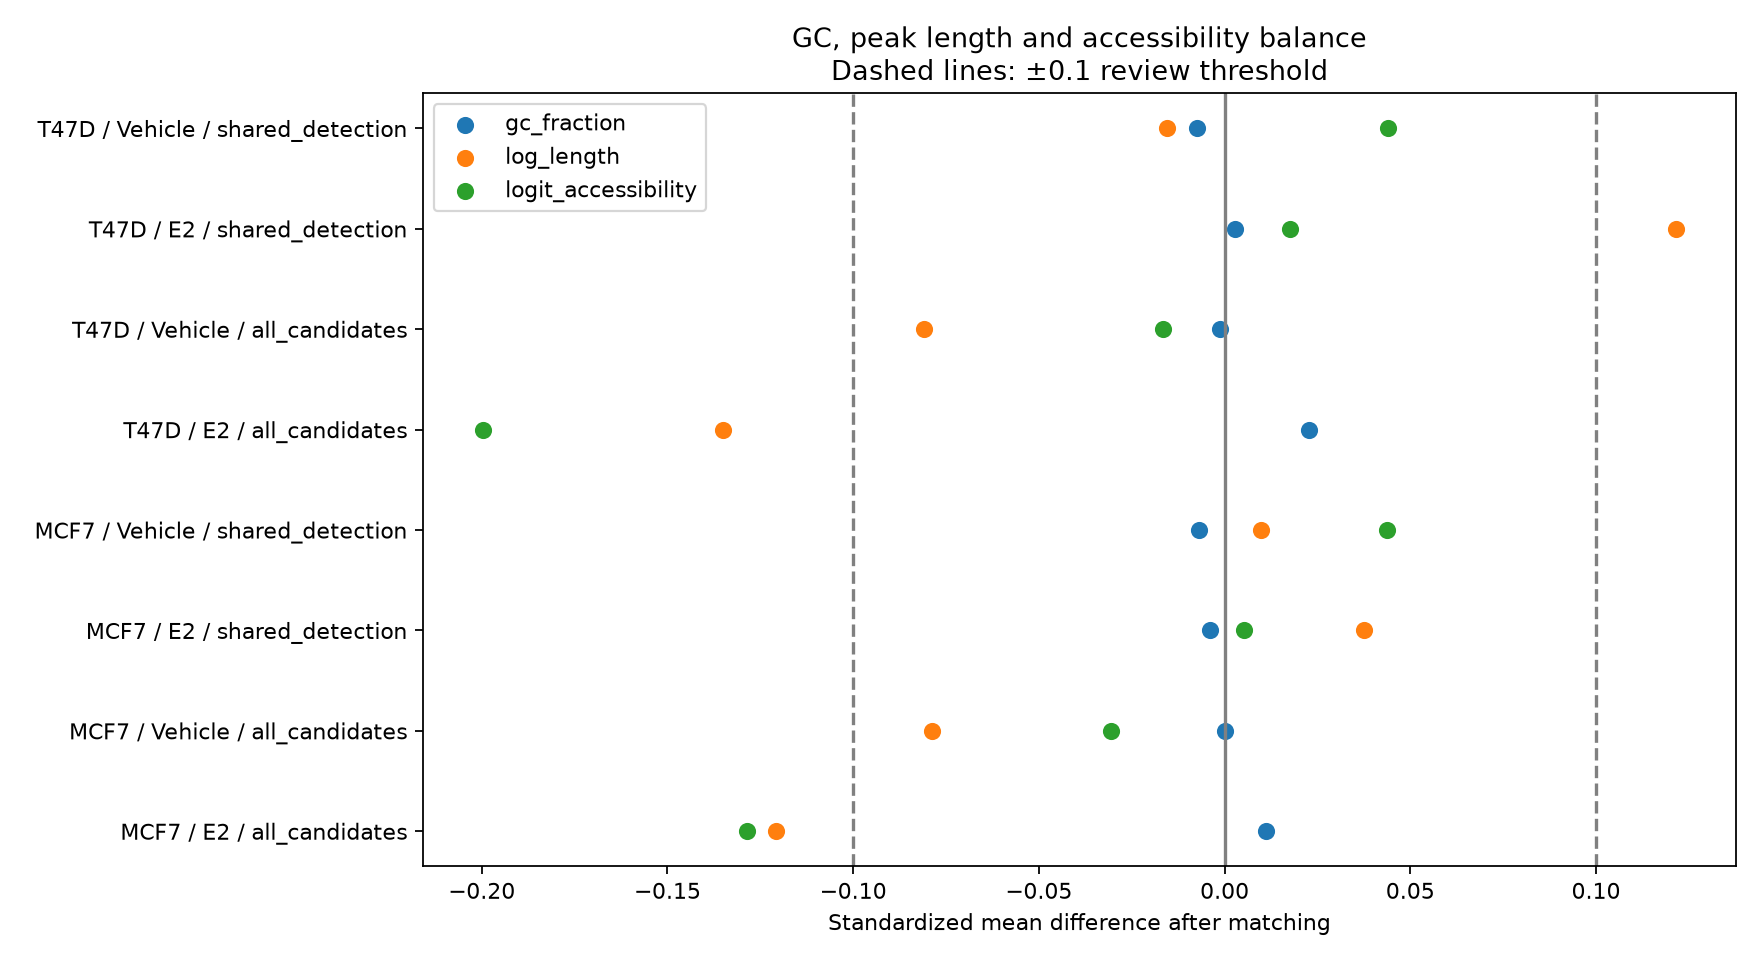

In [5]:
enrichment,matching,report=run_motifs(BASE,CONFIG,REFERENCES,COORDINATE_AUDIT)
report['versions']=VERSIONS
report['executed_in_colab']=IN_COLAB
(BASE/'results/tables/nb07/motif_summary.json').write_text(json.dumps(report,indent=2)+'\n')
from IPython.display import display,Image,Markdown
display(pd.Series(report['sequence_qc_counts'],name='peaks'))
display(matching)
print('Peaks with at least one motif-presence change between coordinate hypotheses:',report['coordinate_changed_peaks'])
display(Image(filename=str(BASE/'results/figures/nb07/background_balance.png')))


## 5. More-accessible and less-accessible peak sets
Both directions are tested for motif enrichment. A motif in closing peaks does not
mean the TF itself is downregulated. Gray bars flag results that do not meet the
combined matching and global-q criteria.

### MCF7

**More accessible under E2**

,motif_id,motif_name,direction,n_matched_pairs,foreground_hit_fraction,background_hit_fraction,paired_log2_odds_smoothed,global_BH_q,matching_acceptable,priority_candidate
19,MA0258.2,ESR2,E2,594,0.553872,0.297980,1.530170,4.512942e-15,False,False
304,MA0112.4,ESR1,E2,594,0.400673,0.237374,1.042721,2.157123e-06,False,False
531,MA1535.2,NR2C1,E2,594,0.563973,0.424242,0.843388,2.558413e-04,False,False
533,MA1536.2,NR2C2,E2,594,0.563973,0.424242,0.843388,2.558413e-04,False,False
750,MA2337.1,Nr1h3,E2,594,0.563973,0.424242,0.843388,2.558413e-04,False,False
827,MA1996.2,Nr1H2,E2,594,0.563973,0.424242,0.843388,2.558413e-04,False,False
829,MA1110.3,Nr1H4,E2,594,0.563973,0.424242,0.843388,2.558413e-04,False,False
507,MA1643.2,NFIB,E2,594,0.451178,0.324916,0.786293,1.442380e-03,False,False
596,MA1150.2,RORB,E2,594,0.168350,0.101010,0.973689,2.163013e-02,False,False
8,MA0119.1,NFIC::TLX1,E2,594,0.303030,0.218855,0.646137,4.722419e-02,False,False


**Less accessible under E2**

,motif_id,motif_name,direction,n_matched_pairs,foreground_hit_fraction,background_hit_fraction,paired_log2_odds_smoothed,global_BH_q,matching_acceptable,priority_candidate
2630,MA2002.2,Zfp335,Vehicle,679,0.166421,0.101620,0.853867,0.025233,True,True
2113,MA0148.5,FOXA1,Vehicle,679,0.228277,0.163476,0.684277,0.058214,True,False
1787,MA0042.2,FOXI1,Vehicle,679,0.175258,0.116348,0.732188,0.058214,True,False
1788,MA0033.2,FOXL1,Vehicle,679,0.175258,0.116348,0.732188,0.058214,True,False
1854,MA0848.1,FOXO4,Vehicle,679,0.175258,0.116348,0.732188,0.058214,True,False
1855,MA0849.1,FOXO6,Vehicle,679,0.175258,0.116348,0.732188,0.058214,True,False
1856,MA0850.1,FOXP3,Vehicle,679,0.175258,0.116348,0.732188,0.058214,True,False
1942,MA2117.1,FOXP4,Vehicle,679,0.175258,0.116348,0.732188,0.058214,True,False
2115,MA1683.2,FOXA3,Vehicle,679,0.175258,0.116348,0.732188,0.058214,True,False
2117,MA0031.2,FOXD1,Vehicle,679,0.175258,0.116348,0.732188,0.058214,True,False


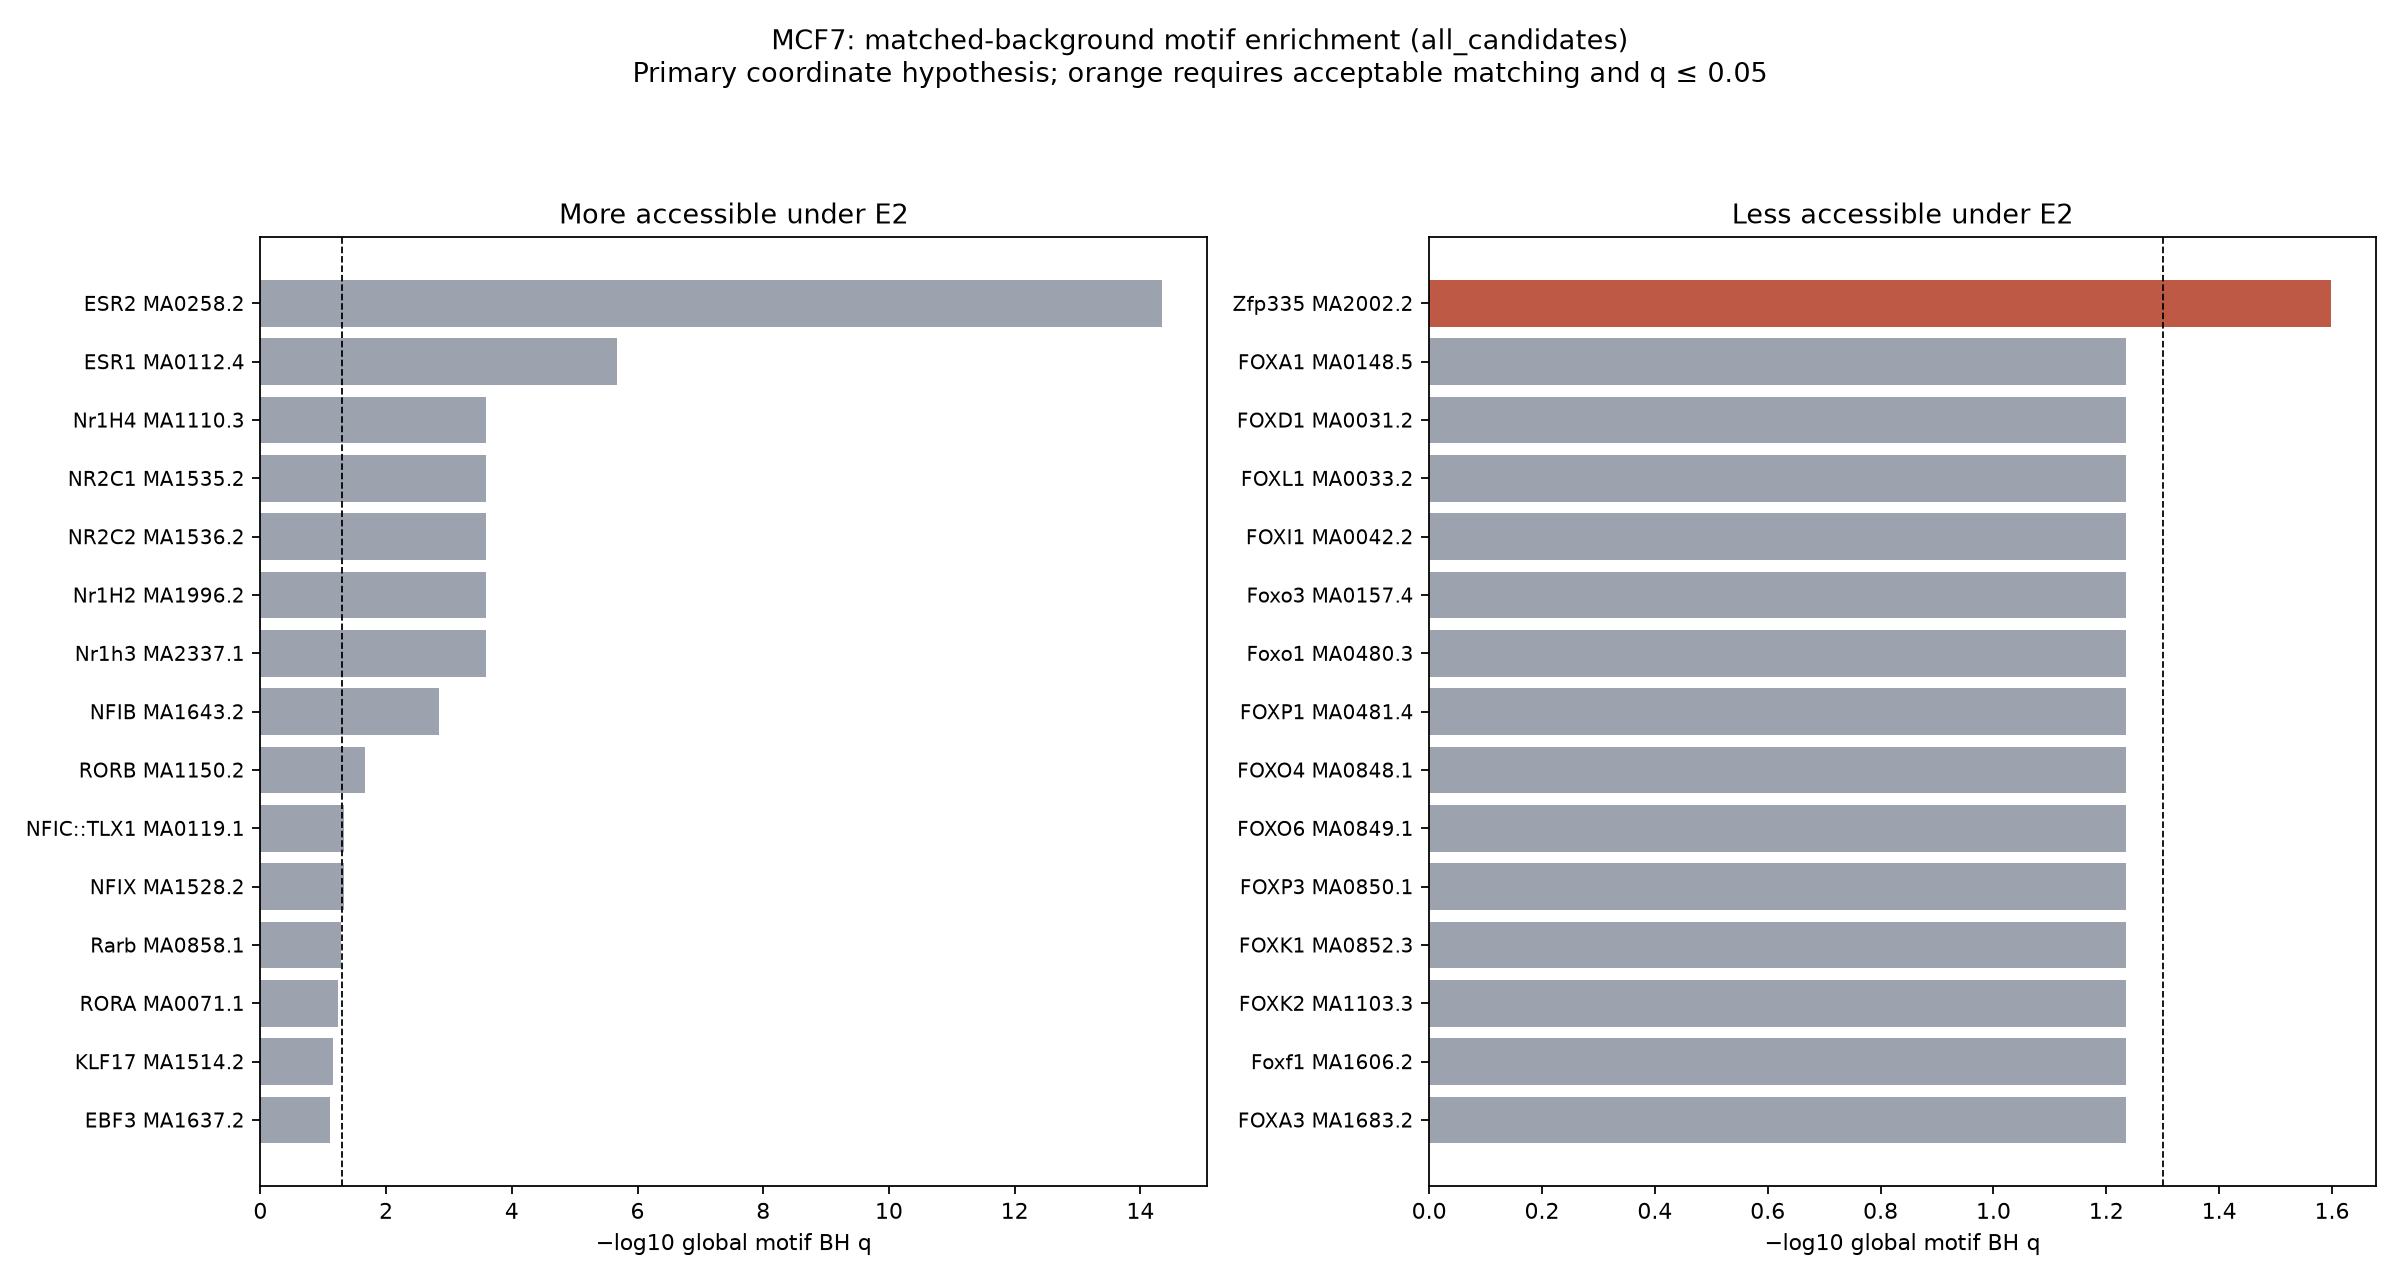

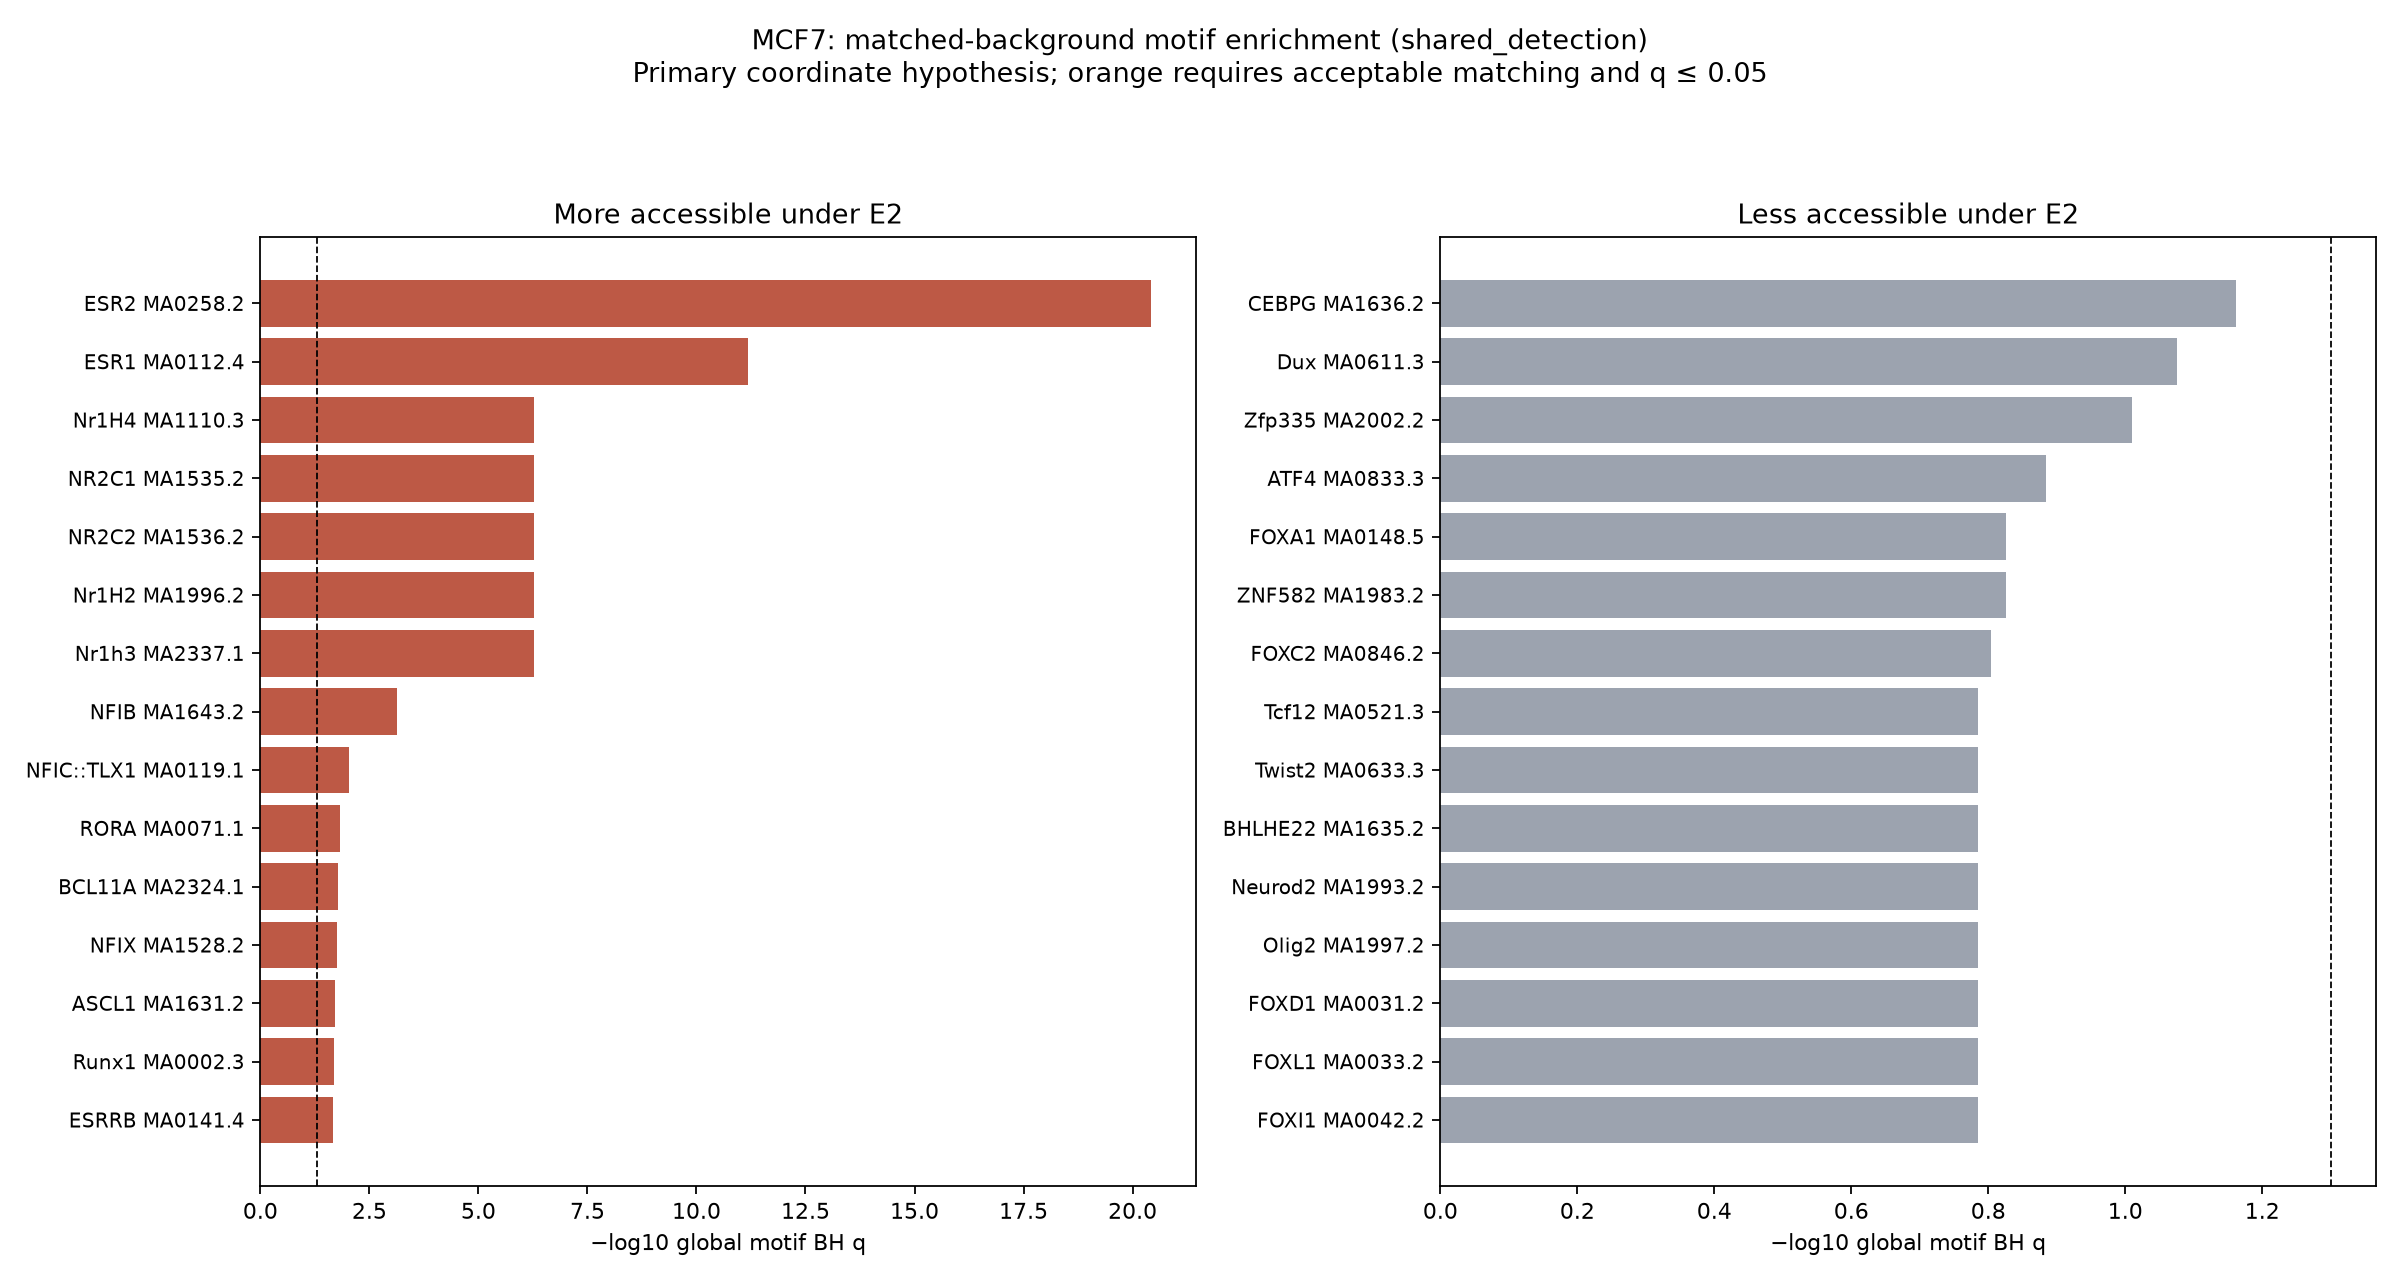

In [6]:
primary=enrichment.loc[(enrichment.cell_line=='MCF7')&(enrichment.scenario=='all_candidates')&
                         (enrichment.coordinate_hypothesis=='zero_based_half_open')]
cols=['motif_id','motif_name','direction','n_matched_pairs','foreground_hit_fraction',
      'background_hit_fraction','paired_log2_odds_smoothed','global_BH_q','matching_acceptable','priority_candidate']
for direction,title in [('E2','More accessible under E2'),('Vehicle','Less accessible under E2')]:
    display(Markdown('**'+title+'**'))
    display(primary.loc[primary.direction==direction].sort_values(['global_BH_q','peak_pair_p']).head(20)[cols])
display(Image(filename=str(BASE/'results/figures/nb07/MCF7_motif_enrichment.png')))
display(Image(filename=str(BASE/'results/figures/nb07/MCF7_motif_enrichment_shared_detection.png')))


### T47D

**More accessible under E2**

,motif_id,motif_name,direction,n_matched_pairs,foreground_hit_fraction,background_hit_fraction,paired_log2_odds_smoothed,global_BH_q,matching_acceptable,priority_candidate
7336,MA0112.4,ESR1,E2,725,0.314483,0.179310,1.110873,6.332773e-07,False,False
7380,MA0478.2,FOSL2,E2,725,0.387586,0.286897,0.706672,4.668170e-03,False,False
7253,MA1634.2,BATF,E2,725,0.295172,0.205517,0.736966,7.286041e-03,False,False
7254,MA0462.3,BATF::JUN,E2,725,0.295172,0.205517,0.736966,7.286041e-03,False,False
7256,MA0835.3,BATF3,E2,725,0.295172,0.205517,0.736966,7.286041e-03,False,False
7261,MA1928.2,BNC2,E2,725,0.295172,0.205517,0.736966,7.286041e-03,False,False
7794,MA1988.2,Atf3,E2,725,0.295172,0.205517,0.736966,7.286041e-03,False,False
7487,MA1515.2,KLF2,E2,725,0.564138,0.468966,0.685204,7.286041e-03,False,False
7246,MA0496.4,MAFK,E2,725,0.405517,0.304828,0.637038,7.286041e-03,False,False
7506,MA0089.3,MAFG::NFE2L1,E2,725,0.280000,0.193103,0.702095,1.095528e-02,False,False


**Less accessible under E2**

,motif_id,motif_name,direction,n_matched_pairs,foreground_hit_fraction,background_hit_fraction,paired_log2_odds_smoothed,global_BH_q,matching_acceptable,priority_candidate
9433,MA0809.3,TEAD4,Vehicle,1464,0.226093,0.170765,0.515721,0.014224,True,True
9431,MA0090.4,TEAD1,Vehicle,1464,0.232923,0.180328,0.491938,0.021630,True,True
8875,MA0808.1,TEAD3,Vehicle,1464,0.187842,0.142077,0.508645,0.034303,True,True
9432,MA1121.2,TEAD2,Vehicle,1464,0.138661,0.097678,0.549246,0.041505,True,True
9223,MA0908.2,HOXD11,Vehicle,1464,0.080601,0.052596,0.701287,0.062388,True,False
8928,MA0158.2,HOXA5,Vehicle,1464,0.047814,0.028005,0.826464,0.125175,True,False
8813,MA0604.1,Atf1,Vehicle,1464,0.086749,0.060792,0.552139,0.164129,True,False
9559,MA0840.2,Creb5,Vehicle,1464,0.111339,0.082650,0.479610,0.164129,True,False
9218,MA0907.2,HOXC13,Vehicle,1464,0.099044,0.072404,0.516962,0.165107,True,False
9022,MA1473.2,CDX4,Vehicle,1464,0.161202,0.129098,0.408740,0.184042,True,False


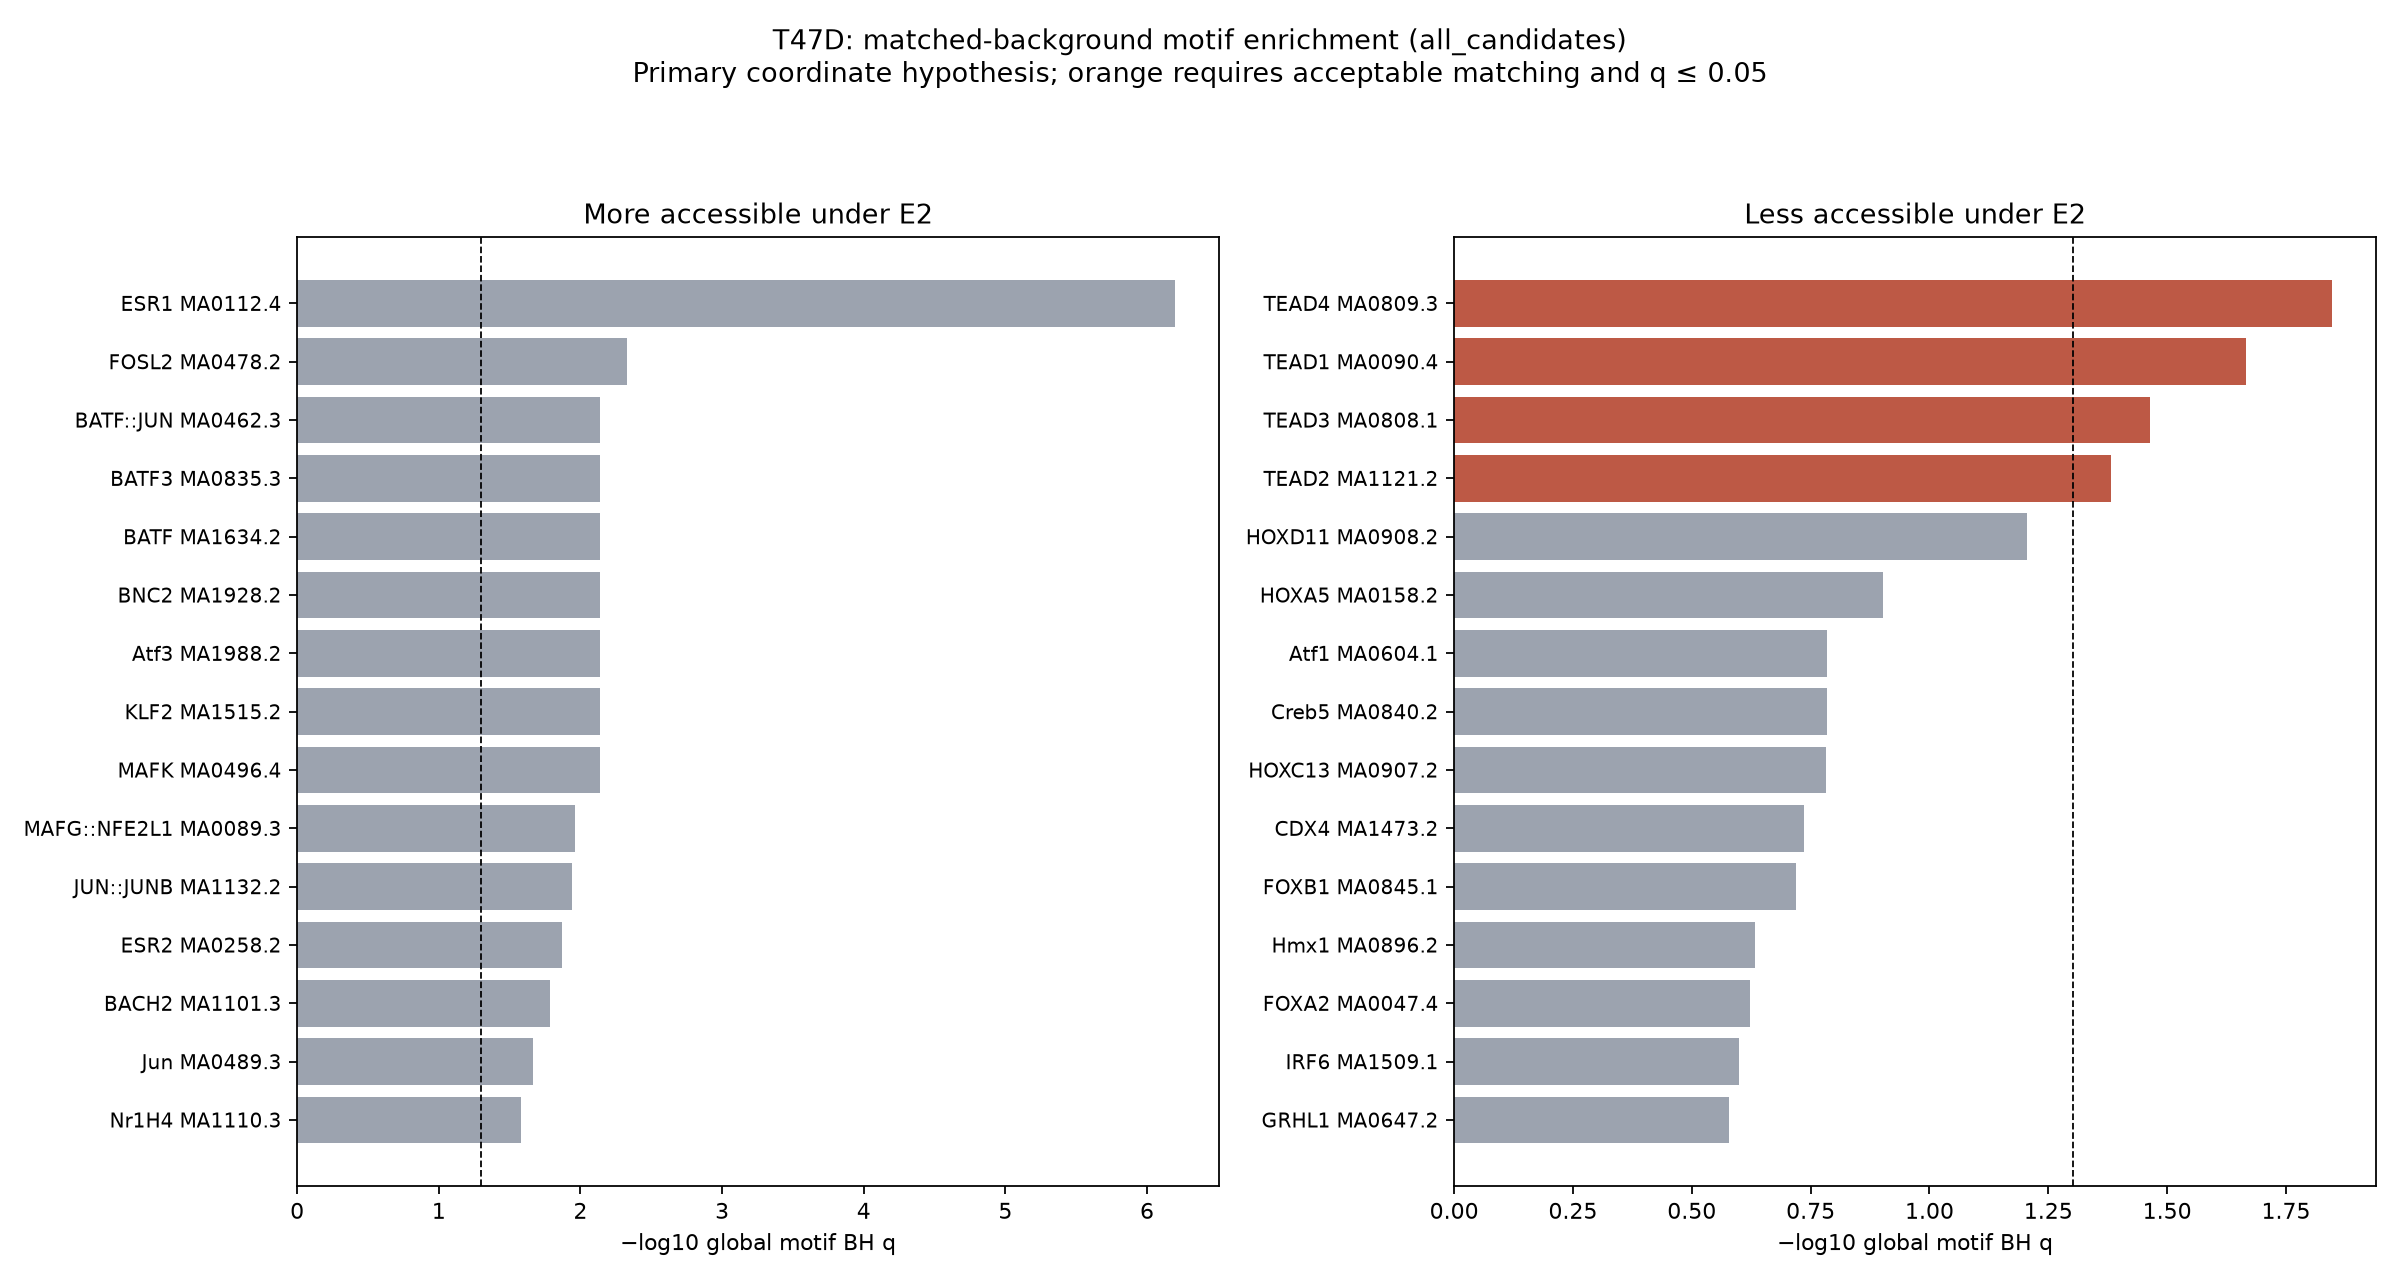

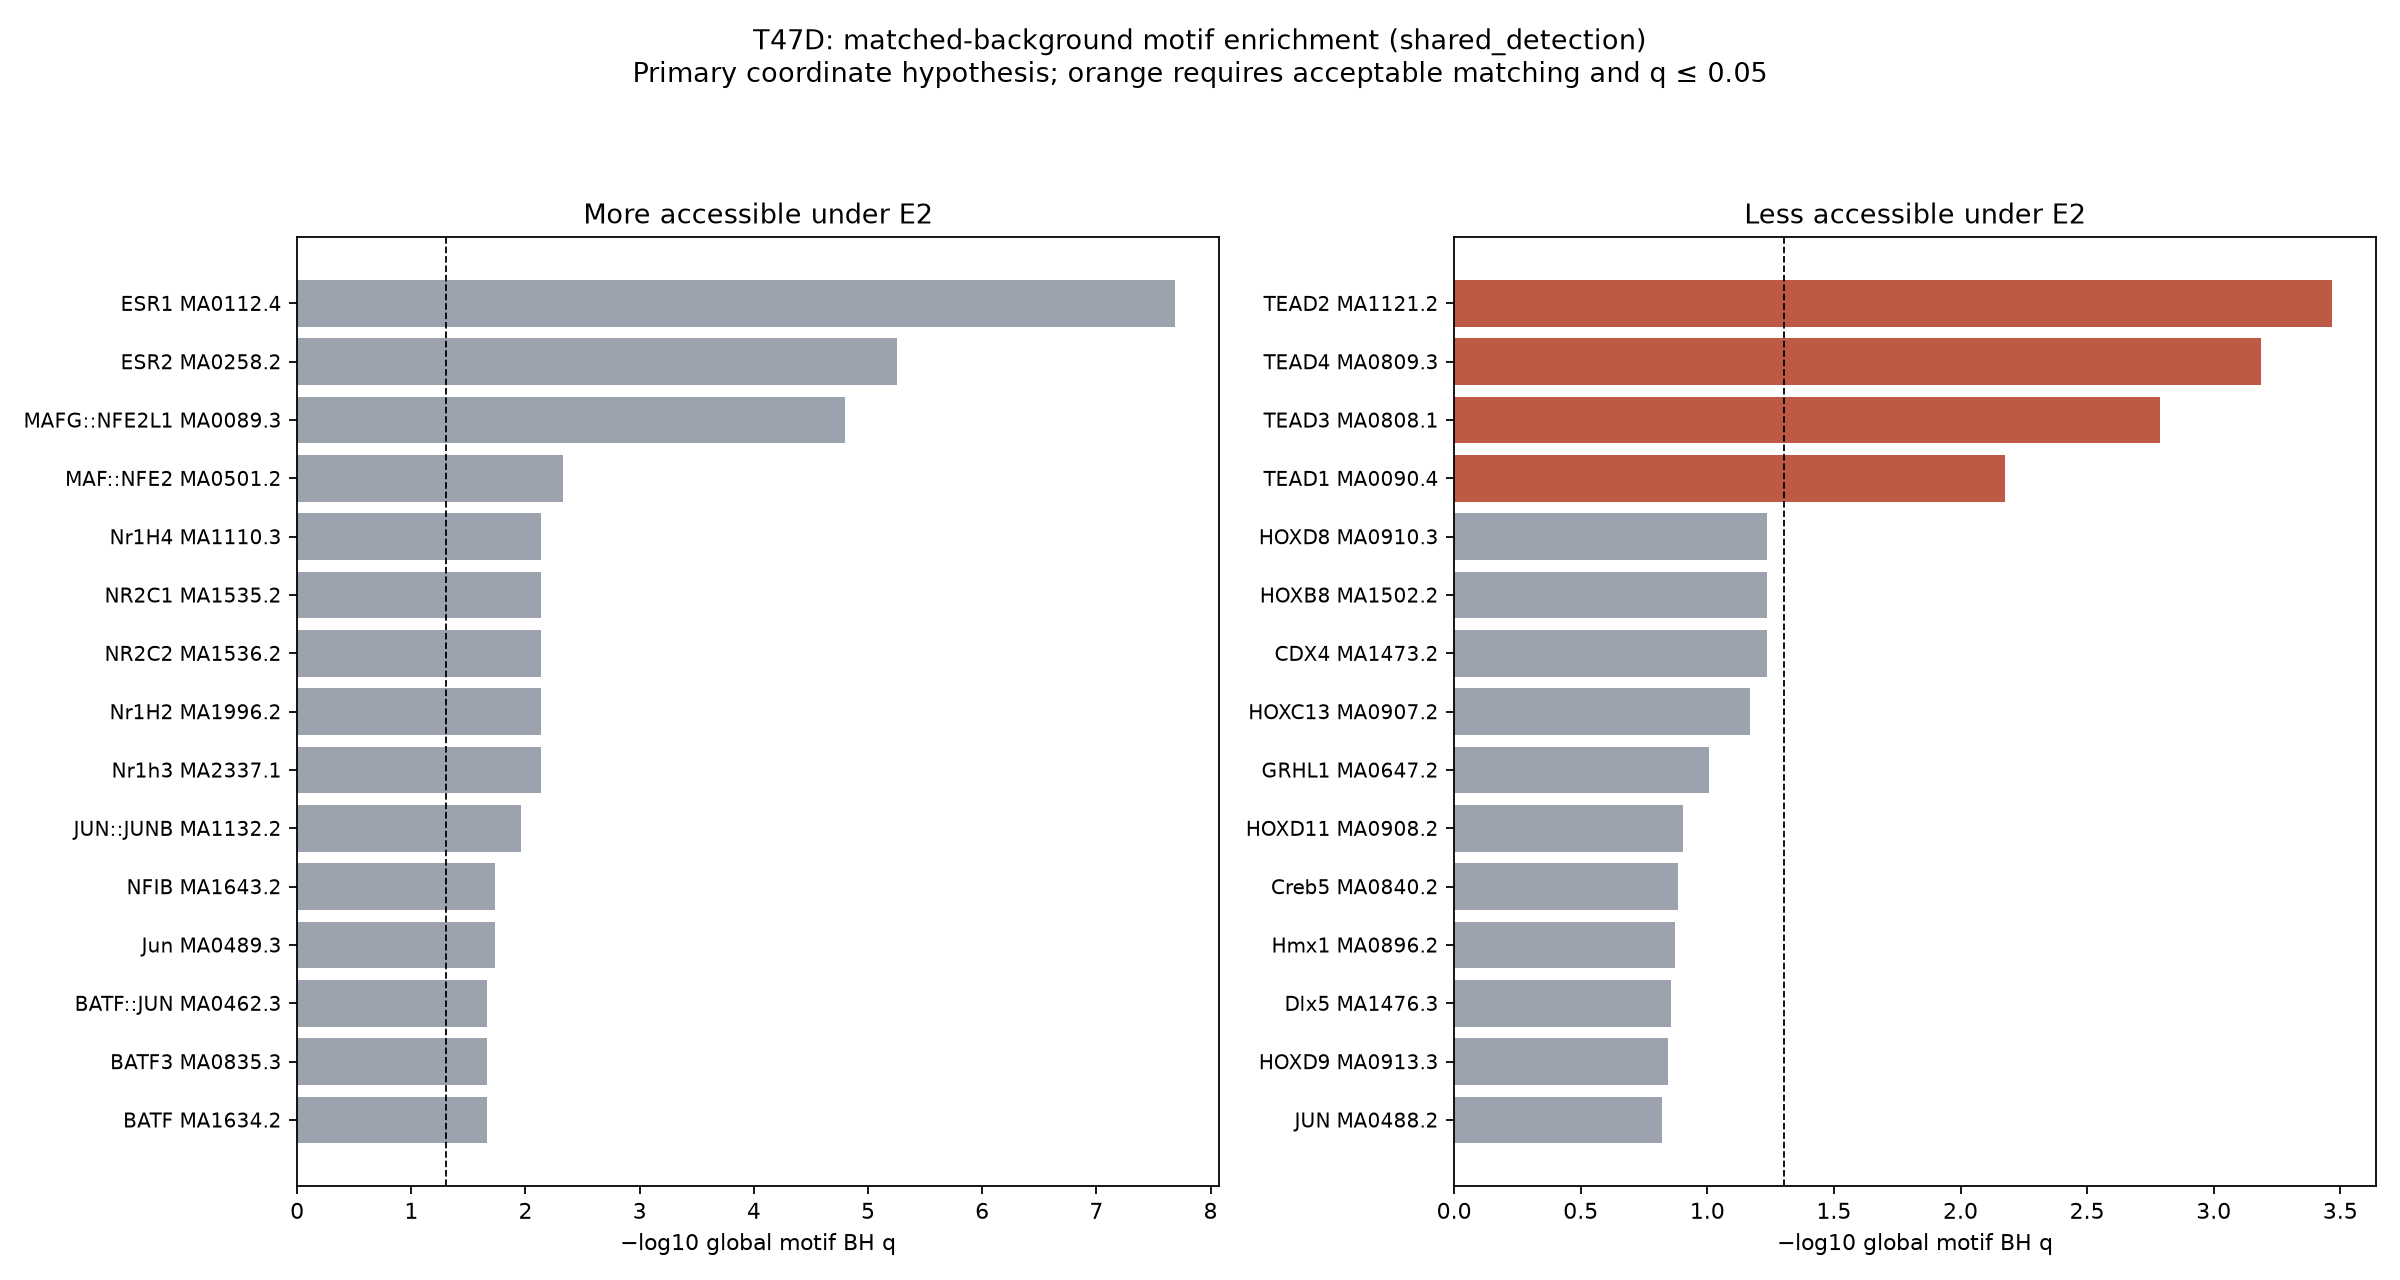

In [7]:
primary=enrichment.loc[(enrichment.cell_line=='T47D')&(enrichment.scenario=='all_candidates')&
                         (enrichment.coordinate_hypothesis=='zero_based_half_open')]
cols=['motif_id','motif_name','direction','n_matched_pairs','foreground_hit_fraction',
      'background_hit_fraction','paired_log2_odds_smoothed','global_BH_q','matching_acceptable','priority_candidate']
for direction,title in [('E2','More accessible under E2'),('Vehicle','Less accessible under E2')]:
    display(Markdown('**'+title+'**'))
    display(primary.loc[primary.direction==direction].sort_values(['global_BH_q','peak_pair_p']).head(20)[cols])
display(Image(filename=str(BASE/'results/figures/nb07/T47D_motif_enrichment.png')))
display(Image(filename=str(BASE/'results/figures/nb07/T47D_motif_enrichment_shared_detection.png')))


## 6. Sensitivity to coordinates and condition-exclusive peaks

In [8]:
sensitivity=pd.read_csv(BASE/'results/tables/nb07/motif_sensitivity.tsv',sep='\t')
primary=enrichment.loc[(enrichment.scenario=='all_candidates')&(enrichment.coordinate_hypothesis=='zero_based_half_open')]
selected=primary.loc[primary.priority_candidate,['cell_line','direction','motif_id']].drop_duplicates()
display(sensitivity.merge(selected,on=['cell_line','direction','motif_id'],how='inner'))
display(enrichment.groupby(['cell_line','direction','scenario','coordinate_hypothesis']).priority_candidate.sum().rename('priority_motifs').reset_index())


,cell_line,direction,motif_id,motif_name,q__all_candidates__zero_based_half_open,q__all_candidates__one_based_closed,q__shared_detection__zero_based_half_open,q__shared_detection__one_based_closed,q_le_005_all_four_scenarios
0,MCF7,Vehicle,MA2002.2,Zfp335,0.025233,0.020924,0.097841,0.074916,False
1,T47D,Vehicle,MA0090.4,TEAD1,0.021630,0.021630,0.006671,0.006671,True
2,T47D,Vehicle,MA0808.1,TEAD3,0.034303,0.034303,0.001634,0.001634,True
3,T47D,Vehicle,MA0809.3,TEAD4,0.014224,0.016310,0.000649,0.000760,True
4,T47D,Vehicle,MA1121.2,TEAD2,0.041505,0.041505,0.000341,0.000341,True


,cell_line,direction,scenario,coordinate_hypothesis,priority_motifs
0,MCF7,E2,all_candidates,one_based_closed,0
1,MCF7,E2,all_candidates,zero_based_half_open,0
2,MCF7,E2,shared_detection,one_based_closed,18
3,MCF7,E2,shared_detection,zero_based_half_open,18
4,MCF7,Vehicle,all_candidates,one_based_closed,1
5,MCF7,Vehicle,all_candidates,zero_based_half_open,1
6,MCF7,Vehicle,shared_detection,one_based_closed,0
7,MCF7,Vehicle,shared_detection,zero_based_half_open,0
8,T47D,E2,all_candidates,one_based_closed,0
9,T47D,E2,all_candidates,zero_based_half_open,0


## 7. TF RNA expression and provisional pathway context
The complete tables include all motifs. The focus below is a contextual view of
estrogen-associated TF labels, not a result-selected confirmatory test. Motif
families can share sequences; RNA expression does not identify which family member
bound a site. Pathway intersections below are proximity evidence only.

In [9]:
rna_context=pd.read_csv(BASE/'results/tables/nb07/motif_TF_RNA_context.tsv',sep='\t')
focus=['ESR1','ESR2','FOXA1','GATA3','FOXM1']
display(rna_context.loc[rna_context.candidate_TF_gene_label.isin(focus)])
focus_ids=rna_context.loc[rna_context.candidate_TF_gene_label.isin(focus),'motif_id'].unique()
display(enrichment.loc[enrichment.motif_id.isin(focus_ids),['cell_line','direction','scenario',
      'coordinate_hypothesis','motif_id','motif_name','global_BH_q','paired_log2_odds_smoothed','priority_candidate']])
pathway_context=pd.read_csv(BASE/'results/tables/nb07/top_motif_pathway_context.tsv',sep='\t')
display(pathway_context.head(40))
print('Full traceable gene/peak and pathway context is saved in top_motif_pathway_context.tsv.')


,cell_line,motif_id,motif_name,candidate_TF_gene_label,RNA_gene_tested,mapping_policy,approx_log2FC_E2_vs_Vehicle,cell_level_BH_q,pct_E2
24,MCF7,MA0258.2,ESR2,ESR2,True,case-normalized label; variant suffix removed;...,1.359435,5.661499e-31,0.207662
326,MCF7,MA0112.4,ESR1,ESR1,True,case-normalized label; variant suffix removed;...,0.085361,2.422719e-02,0.947400
403,MCF7,MA0148.5,FOXA1,FOXA1,True,case-normalized label; variant suffix removed;...,-0.209827,2.897125e-05,0.604439
859,MCF7,MA0037.5,Gata3,GATA3,True,case-normalized label; variant suffix removed;...,-0.043523,1.607720e-01,0.963819
979,T47D,MA0258.2,ESR2,ESR2,True,case-normalized label; variant suffix removed;...,0.469754,7.634149e-05,0.164937
1281,T47D,MA0112.4,ESR1,ESR1,True,case-normalized label; variant suffix removed;...,-0.703425,1.824671e-143,0.955961
1358,T47D,MA0148.5,FOXA1,FOXA1,True,case-normalized label; variant suffix removed;...,-0.242110,5.894339e-07,0.625526
1814,T47D,MA0037.5,Gata3,GATA3,True,case-normalized label; variant suffix removed;...,-0.358470,9.725803e-49,0.949790


,cell_line,direction,scenario,coordinate_hypothesis,motif_id,motif_name,global_BH_q,paired_log2_odds_smoothed,priority_candidate
19,MCF7,E2,all_candidates,zero_based_half_open,MA0258.2,ESR2,4.512942e-15,1.530170,False
304,MCF7,E2,all_candidates,zero_based_half_open,MA0112.4,ESR1,2.157123e-06,1.042721,False
355,MCF7,E2,all_candidates,zero_based_half_open,MA0148.5,FOXA1,1.000000e+00,-0.158504,False
788,MCF7,E2,all_candidates,zero_based_half_open,MA0037.5,Gata3,1.000000e+00,-0.241008,False
898,MCF7,E2,all_candidates,one_based_closed,MA0258.2,ESR2,4.512942e-15,1.530170,False
...,...,...,...,...,...,...,...,...,...
13094,T47D,Vehicle,shared_detection,zero_based_half_open,MA0037.5,Gata3,5.424216e-01,0.358631,False
13204,T47D,Vehicle,shared_detection,one_based_closed,MA0258.2,ESR2,1.000000e+00,-0.235911,False
13489,T47D,Vehicle,shared_detection,one_based_closed,MA0112.4,ESR1,1.000000e+00,-0.147342,False
13540,T47D,Vehicle,shared_detection,one_based_closed,MA0148.5,FOXA1,3.277382e-01,0.382720,False


,cell_line,scenario,direction,motif_id,motif_name,pathway,n_provisional_genes,genes,peaks,rna_NES,rna_GSEA_FDR,nb06_fraction_same_direction,interpretation
0,MCF7,shared_detection,E2,MA0258.2,ESR2,HALLMARK_TNFA_SIGNALING_VIA_NFKB,1,TIPARP,chr3-156637362-156638293,-1.281805,0.202528,0.514851,motif-bearing peak proximity only; not TF targ...
1,MCF7,shared_detection,E2,MA0258.2,ESR2,HALLMARK_HYPOXIA,2,SLC6A6;TIPARP,chr3-14412772-14413555;chr3-156637362-156638293,-1.043188,0.508954,0.495495,motif-bearing peak proximity only; not TF targ...
2,MCF7,shared_detection,E2,MA0258.2,ESR2,HALLMARK_CHOLESTEROL_HOMEOSTASIS,1,ACTG1,chr17-81519053-81519822,-1.476237,0.109895,0.622642,motif-bearing peak proximity only; not TF targ...
3,MCF7,shared_detection,E2,MA0258.2,ESR2,HALLMARK_MITOTIC_SPINDLE,2,DLG1;PREX1,chr20-48864419-48865326;chr3-197367102-197367953,2.066772,0.000134,0.380368,motif-bearing peak proximity only; not TF targ...
4,MCF7,shared_detection,E2,MA0258.2,ESR2,HALLMARK_APOPTOSIS,1,RARA,chr17-40314264-40315172,0.976333,0.596468,0.490000,motif-bearing peak proximity only; not TF targ...
5,MCF7,shared_detection,E2,MA0258.2,ESR2,HALLMARK_ESTROGEN_RESPONSE_EARLY,16,ARL3;ASB13;CISH;FHL2;FKBP4;GREB1;IGFBP4;ITPK1;...,chr10-93434843-93435759;chr10-102710444-102711...,2.870268,0.000000,0.654088,motif-bearing peak proximity only; not TF targ...
6,MCF7,shared_detection,E2,MA0258.2,ESR2,HALLMARK_ESTROGEN_RESPONSE_LATE,12,ARL3;CISH;FKBP4;IGFBP4;ITPK1;LLGL2;MYOF;PGR;RA...,chr10-93434843-93435759;chr10-102710444-102711...,2.857860,0.000000,0.676056,motif-bearing peak proximity only; not TF targ...
7,MCF7,shared_detection,E2,MA0258.2,ESR2,HALLMARK_ANDROGEN_RESPONSE,1,ZMIZ1,chr10-79128390-79129468;chr10-79126855-79127775,1.050358,0.496274,0.355263,motif-bearing peak proximity only; not TF targ...
8,MCF7,shared_detection,E2,MA0258.2,ESR2,HALLMARK_MYOGENESIS,1,TPM3,chr1-154190294-154191197,0.992090,0.585149,0.581395,motif-bearing peak proximity only; not TF targ...
9,MCF7,shared_detection,E2,MA0258.2,ESR2,HALLMARK_APICAL_JUNCTION,2,ACTG1;DLG1,chr17-81519053-81519822;chr3-197367102-197367953,-1.086264,0.528156,0.422680,motif-bearing peak proximity only; not TF targ...


Full traceable gene/peak and pathway context is saved in top_motif_pathway_context.tsv.


## 8. Interpretation
Prioritize motifs that have adequate matching, survive global correction, and
remain informative across coordinate and condition-exclusive-peak sensitivity
analyses. Compare the two cell lines without treating them as biological
replicates. Interpret related motif families together.

The experiment still lacks identifiable biological replicates. This analysis
does not establish TF binding, TF activation/inhibition, or causal pathway
regulation. The coordinate origin remains historically unresolved even if the
two boundary hypotheses give nearly identical results.


## Initial run interpretation (11 October 2026)

The analysis scanned **879 JASPAR motifs across 48,636 eligible peaks** from the
48,976-peak union of the two nb05 testing sets. Sequence QC excluded 324 blacklist
overlaps, 14 nonstandard-chromosome peaks and 2 ambiguous sequences.

Both coordinate hypotheses were tested. They differed for 7,971 peak–motif
presence entries across 4,660 peaks. This sensitivity check does not establish
which original coordinate convention was used.

| Cell line / peak direction | Matching passes, all candidates | Matching passes, shared detection | Priority motifs, all candidates | Priority motifs, shared detection |
|---|---|---|---:|---:|
| MCF7 / more accessible under E2 | No | Yes | 0 | 18 |
| MCF7 / less accessible under E2 | Yes | Yes | 1 | 0 |
| T47D / more accessible under E2 | No | No | 0 | 0 |
| T47D / less accessible under E2 | Yes | Yes | 4 | 4 |

Counts use the shorter coordinate hypothesis and require both acceptable matching
and global motif BH q <= 0.05. A zero caused by inadequate matching is **not**
evidence of no motif enrichment.

- **MCF7 opening peaks:** ESR1/ESR2-related motifs are enriched in the shared-
  detection analysis, where matching passes (global q approximately 6.6e-12
  and 3.7e-21). These related sequence motifs do not distinguish actual ESR1
  versus ESR2 binding or establish TF activity.
- **T47D closing peaks:** the TEAD1–4 motif family passes the matching and global-q
  criteria in both detection scenarios. These are related motif models, not four
  independent regulatory discoveries; closing-peak enrichment does not prove
  that TEAD activity is inhibited.
- **Matching limitations:** the all-candidate opening sets have residual length
  and accessibility imbalance (maximum absolute SMD approximately 0.129 in MCF7
  and 0.200 in T47D). T47D shared-detection opening peaks retain length imbalance
  (SMD approximately 0.122). Their enrichment statistics remain visible, but these
  groups are not promoted to priority findings.
- The single MCF7 closing-peak priority motif does not pass global q in the shared-
  detection analysis, so this result is sensitive to the foreground definition.

The coordinate and matching flags, no-biological-replicate limitation, and
provisional motif-label and nearby-gene assignments must accompany these findings.
